<a href="https://colab.research.google.com/github/PedroPereiraJPPF/solar-energy-ml/blob/main/ProjetoSolar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

:# Sistema de Previsao e Monitoramento de Geracao Solar Fotovoltaica

**Disciplina:** Aprendizagem de Maquina
**Professora:** Amanda Gondim
**Aluno:** Joao Pedro Pereira Frutuoso
**Universidade:** UFERSA - Universidade Federal Rural do Semi-Arido

---

## Objetivo

Construir um sistema de apoio a decisao que estima a geracao de energia de uma usina solar a partir apenas das condicoes climaticas (irradiacao, temperatura e hora). Por nao depender de nenhuma leitura de geracao como entrada, o mesmo modelo atende a dois usos:

1. **Previsao** - estimar a geracao esperada para condicoes futuras (planejamento).
2. **Monitoramento** - comparar a geracao real medida com a esperada; um desvio relevante indica possivel falha ou perda de desempenho.

O projeto entrega duas tarefas, ambas a partir do clima:
- **Regressao**: preve a potencia CA esperada (kW).
- **Classificacao**: preve se o periodo sera de baixa geracao (apoio ao planejamento).

Esse objetivo e mantido do inicio ao fim.

**Dataset:** Solar Power Generation Data - Kaggle (anikannal/solar-power-generation-data)
**Periodo:** 34 dias | Intervalo: 15 minutos | Duas usinas solares

---

## 0. Instalação e Importação de Bibliotecas

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')
COLORS = ['#F4A300', '#1E88E5', '#43A047', '#E53935', '#8E24AA']

---
## 1. Carregamento dos Dados

Link dataSet: https://www.kaggle.com/datasets/anikannal/solar-power-generation-data


In [32]:
from google.colab import drive
drive.mount('/content/drive')

GEN1_PATH    = '/content/drive/MyDrive/MachineLearningFinal/Plant_1_Generation_Data.csv'
SENSOR1_PATH = '/content/drive/MyDrive/MachineLearningFinal/Plant_1_Weather_Sensor_Data.csv'
GEN2_PATH    = '/content/drive/MyDrive/MachineLearningFinal/Plant_2_Generation_Data.csv'
SENSOR2_PATH = '/content/drive/MyDrive/MachineLearningFinal/Plant_2_Weather_Sensor_Data.csv'

gen1    = pd.read_csv(GEN1_PATH)
sensor1 = pd.read_csv(SENSOR1_PATH)
gen2    = pd.read_csv(GEN2_PATH)
sensor2 = pd.read_csv(SENSOR2_PATH)

print('=== Planta 1 — Geração ===')
print(f'Shape: {gen1.shape} | Colunas: {list(gen1.columns)}')
print('\n=== Planta 1 — Sensores ===')
print(f'Shape: {sensor1.shape} | Colunas: {list(sensor1.columns)}')
print('\n=== Planta 2 — Geração ===')
print(f'Shape: {gen2.shape}')
print('\n=== Planta 2 — Sensores ===')
print(f'Shape: {sensor2.shape}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Planta 1 — Geração ===
Shape: (68778, 7) | Colunas: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

=== Planta 1 — Sensores ===
Shape: (3182, 6) | Colunas: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

=== Planta 2 — Geração ===
Shape: (67698, 7)

=== Planta 2 — Sensores ===
Shape: (3259, 6)


---
## 2. Pre-Processamento

Etapas:
- Conversao de timestamps
- Agregacao da geracao por instante (soma dos inversores)
- Merge entre geracao e sensores climaticos
- Combinacao das duas plantas
- Verificacao de valores ausentes e de plausibilidade fisica
- Engenharia de atributos (hora, periodo do dia)
- Definicao do alvo de classificacao (baixa geracao)

In [33]:
# ── 2.1 Conversão de Timestamps ───────────────────────────────────────────────
for df, col in [(gen1, 'DATE_TIME'), (sensor1, 'DATE_TIME'),
                (gen2, 'DATE_TIME'), (sensor2, 'DATE_TIME')]:
    df[col] = pd.to_datetime(df[col], dayfirst=True)

print('Timestamps convertidos.')
gen1.head(2)

Timestamps convertidos.


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0


In [34]:
# 2.2 Agregação: geração por timestamp (soma de todos os inversores)
# Cada planta tem cerca de 22 inversores, aqui é feita a soma dos dados de geração dos inversores por timestamp, se dois inversores tem geração no mesmo momento elas são somadas.

def agregar_geracao(df_gen):
    return df_gen.groupby('DATE_TIME').agg(
        DC_POWER      = ('DC_POWER',      'sum'),
        AC_POWER      = ('AC_POWER',      'sum'),
        DAILY_YIELD   = ('DAILY_YIELD',   'sum'),
        TOTAL_YIELD   = ('TOTAL_YIELD',   'sum')
    ).reset_index()

gen1_agg = agregar_geracao(gen1)
gen2_agg = agregar_geracao(gen2)

print(f'Geração P1 após agregação: {gen1_agg.shape}')
print(f'Geração P2 após agregação: {gen2_agg.shape}')

Geração P1 após agregação: (3158, 5)
Geração P2 após agregação: (3259, 5)


In [35]:
# ── 2.3 Merge geração + sensores para cada planta ─────────────────────────────
# Essa etapa é para transformar tudo em uma base somente

def merge_planta(df_gen, df_sensor, plant_id):
    df = pd.merge(df_gen, df_sensor, on='DATE_TIME', how='inner')
    df['PLANT_ID'] = plant_id
    return df

p1 = merge_planta(gen1_agg, sensor1, plant_id=1)
p2 = merge_planta(gen2_agg, sensor2, plant_id=2)

# Combina as duas plantas
df = pd.concat([p1, p2], ignore_index=True).sort_values('DATE_TIME').reset_index(drop=True)

print(f'Dataset combinado: {df.shape}')
df.head(15)

Dataset combinado: (6416, 10)


,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,0.0,0.000000,1.435817e+08,1,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,0.0,0.0,48899.938095,1.418960e+10,2,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
2,2020-05-15 00:15:00,0.0,0.0,28401.000000,1.418960e+10,2,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
3,2020-05-15 00:15:00,0.0,0.0,0.000000,1.435817e+08,1,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
4,2020-05-15 00:30:00,0.0,0.0,0.000000,1.435817e+08,1,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
5,2020-05-15 00:30:00,0.0,0.0,28401.000000,1.418960e+10,2,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
6,2020-05-15 00:45:00,0.0,0.0,0.000000,1.435817e+08,1,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
7,2020-05-15 00:45:00,0.0,0.0,28401.000000,1.418960e+10,2,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
8,2020-05-15 01:00:00,0.0,0.0,26516.000000,1.418960e+10,2,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0
9,2020-05-15 01:00:00,0.0,0.0,0.000000,1.507616e+08,1,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [36]:
# ── 2.4 Inspeção de Valores Ausentes
# Não serviu para esse dataset pois ele não tem valores ausentes, mas pode ser necessário em uma possivel ampliação do dataset

print('=== Valores Ausentes ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Ausentes': missing, 'Percentual (%)': missing_pct})
print(missing_df[missing_df['Ausentes'] > 0])

# Estratégia: preencher com mediana (robusto a outliers)
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

print(f'\n Valores ausentes após tratamento: {df.isnull().sum().sum()}')

=== Valores Ausentes ===
Empty DataFrame
Columns: [Ausentes, Percentual (%)]
Index: []

 Valores ausentes após tratamento: 0


In [37]:
# 2.5 Verificacao de plausibilidade
# Nao se aplica remocao por IQR: a geracao tem distribuicao naturalmente
# assimetrica (zero a noite, alta no pico do dia), e os picos diurnos sao
# legitimos, nao outliers. A unica condicao impossivel e geracao negativa.
print('Valores negativos por coluna:')
for col in ['AC_POWER', 'DC_POWER']:
    print(f'  {col}: {(df[col] < 0).sum()}')

antes = len(df)
df = df[(df['AC_POWER'] >= 0) & (df['DC_POWER'] >= 0)].reset_index(drop=True)
print(f'Linhas removidas: {antes - len(df)} | Shape: {df.shape}')

Valores negativos por coluna:
  AC_POWER: 0
  DC_POWER: 0
Linhas removidas: 0 | Shape: (6416, 10)


In [38]:
# 2.6 Engenharia de atributos
df['HORA']       = df['DATE_TIME'].dt.hour
df['MES']        = df['DATE_TIME'].dt.month
df['DIA_SEMANA'] = df['DATE_TIME'].dt.dayofweek
df['DATA']       = df['DATE_TIME'].dt.date

def periodo_dia(hora):
    if hora < 6:    return 'Madrugada'
    elif hora < 12: return 'Manha'
    elif hora < 18: return 'Tarde'
    else:           return 'Noite'
df['PERIODO'] = df['HORA'].apply(periodo_dia)

print('Atributos criados:', ['HORA', 'MES', 'DIA_SEMANA', 'PERIODO'])
df[['DATE_TIME', 'HORA', 'PERIODO', 'AC_POWER', 'PLANT_ID']].head(6)

Atributos criados: ['HORA', 'MES', 'DIA_SEMANA', 'PERIODO']


,DATE_TIME,HORA,PERIODO,AC_POWER,PLANT_ID
0,2020-05-15 00:00:00,0,Madrugada,0.0,1
1,2020-05-15 00:00:00,0,Madrugada,0.0,2
2,2020-05-15 00:15:00,0,Madrugada,0.0,2
3,2020-05-15 00:15:00,0,Madrugada,0.0,1
4,2020-05-15 00:30:00,0,Madrugada,0.0,1
5,2020-05-15 00:30:00,0,Madrugada,0.0,2


In [39]:
# 2.7 Alvo de classificacao: BAIXA_GERACAO
# Objetivo: prever, a partir do clima, se o periodo tera baixa geracao -
# util para programar manutencoes em janelas de menor producao.
# Considera apenas periodos com sol (irradiacao > 0.1). O limiar e o 40o
# percentil da geracao diurna de CADA planta, ja que as plantas tem
# capacidades distintas. Os 40% de menor geracao sao rotulados como baixa.
df_dia = df[df['IRRADIATION'] > 0.1].copy()
limiares_ger = df_dia.groupby('PLANT_ID')['AC_POWER'].quantile(0.40)
print('Limiar de baixa geracao (40o percentil diurno) por planta:')
print(limiares_ger)

df['LIMIAR_GER'] = df['PLANT_ID'].map(limiares_ger)
df['BAIXA_GERACAO'] = np.where(
    (df['IRRADIATION'] > 0.1) & (df['AC_POWER'] < df['LIMIAR_GER']),
    1, 0
)
df = df.drop(columns=['LIMIAR_GER'])

dia_mask = df['IRRADIATION'] > 0.1
print('\nDistribuicao do alvo (periodos diurnos):')
print(df.loc[dia_mask, 'BAIXA_GERACAO'].value_counts())
print(f'Proporcao de baixa geracao: {df.loc[dia_mask, "BAIXA_GERACAO"].mean()*100:.1f}%')

Limiar de baixa geracao (40o percentil diurno) por planta:
PLANT_ID
1    12855.087500
2    10673.723905
Name: AC_POWER, dtype: float64

Distribuicao do alvo (periodos diurnos):
BAIXA_GERACAO
0    1673
1    1116
Name: count, dtype: int64
Proporcao de baixa geracao: 40.0%


In [40]:
# ── 2.8 Resumo Final do Dataset Processado ────────────────────────────────────
print('=== Informações do Dataset Final ===')
print(df.info())
print('\n=== Estatísticas Descritivas ===')
df.describe().round(2)

=== Informações do Dataset Final ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6416 entries, 0 to 6415
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   DATE_TIME            6416 non-null   datetime64[ns]
 1   DC_POWER             6416 non-null   float64       
 2   AC_POWER             6416 non-null   float64       
 3   DAILY_YIELD          6416 non-null   float64       
 4   TOTAL_YIELD          6416 non-null   float64       
 5   PLANT_ID             6416 non-null   int64         
 6   SOURCE_KEY           6416 non-null   object        
 7   AMBIENT_TEMPERATURE  6416 non-null   float64       
 8   MODULE_TEMPERATURE   6416 non-null   float64       
 9   IRRADIATION          6416 non-null   float64       
 10  HORA                 6416 non-null   int32         
 11  MES                  6416 non-null   int32         
 12  DIA_SEMANA           6416 non-null   int32         
 

,DATE_TIME,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HORA,MES,DIA_SEMANA,BAIXA_GERACAO
count,6416,6416.00,6416.00,6416.00,6.416000e+03,6416.00,6416.00,6416.00,6416.00,6416.00,6416.00,6416.00,6416.00
mean,2020-06-01 03:19:58.784289536,36338.09,5844.95,70094.33,7.027618e+09,1.51,26.83,31.99,0.23,11.56,5.51,3.00,0.17
min,2020-05-15 00:00:00,0.00,0.00,0.00,0.000000e+00,1.00,20.40,18.14,0.00,0.00,5.00,0.00,0.00
25%,2020-05-23 17:30:00,0.00,0.00,10598.24,1.536211e+08,1.00,23.67,22.47,0.00,6.00,5.00,1.00,0.00
50%,2020-06-01 06:15:00,1264.47,638.47,71595.00,9.777357e+09,2.00,25.97,26.48,0.02,12.00,6.00,3.00,0.00
75%,2020-06-09 15:03:45,17784.79,11898.46,120673.00,1.419024e+10,2.00,29.37,40.93,0.45,18.00,6.00,5.00,0.00
max,2020-06-17 23:45:00,298937.79,29150.21,193770.00,1.419408e+10,2.00,39.18,66.64,1.22,23.00,6.00,6.00,1.00
std,NaN,69582.97,7576.96,57787.31,6.825671e+09,0.50,3.93,11.84,0.31,6.90,0.50,2.04,0.38


---
## 3. Analise Exploratoria

Tres perguntas ligadas ao objetivo:

1. O que determina a geracao? (define os atributos da regressao)
2. Como a geracao varia ao longo do dia? (justifica o uso da hora)
3. As duas plantas geram de forma diferente? (justifica PLANT_ID)

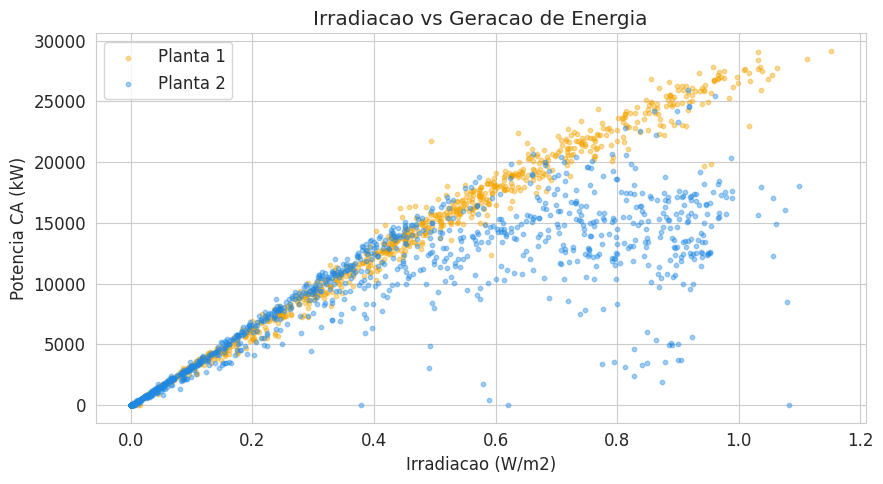

A geracao cresce de forma quase linear com a irradiacao: e o atributo mais relevante para a regressao.


In [41]:
# 3.1 Relacao entre irradiacao e geracao
# Mostra o principal fator que determina a potencia gerada.
amostra = df[df['IRRADIATION'] > 0].sample(min(2000, (df['IRRADIATION'] > 0).sum()), random_state=42)

plt.figure(figsize=(9, 5))
for plant, color in zip([1, 2], [COLORS[0], COLORS[1]]):
    sub = amostra[amostra['PLANT_ID'] == plant]
    plt.scatter(sub['IRRADIATION'], sub['AC_POWER'], s=10, alpha=0.4,
                color=color, label=f'Planta {plant}')
plt.xlabel('Irradiacao (W/m2)')
plt.ylabel('Potencia CA (kW)')
plt.title('Irradiacao vs Geracao de Energia')
plt.legend()
plt.tight_layout()
plt.savefig('aed_irradiacao_geracao.png', dpi=150, bbox_inches='tight')
plt.show()

print('A geracao cresce de forma quase linear com a irradiacao: e o atributo mais relevante para a regressao.')

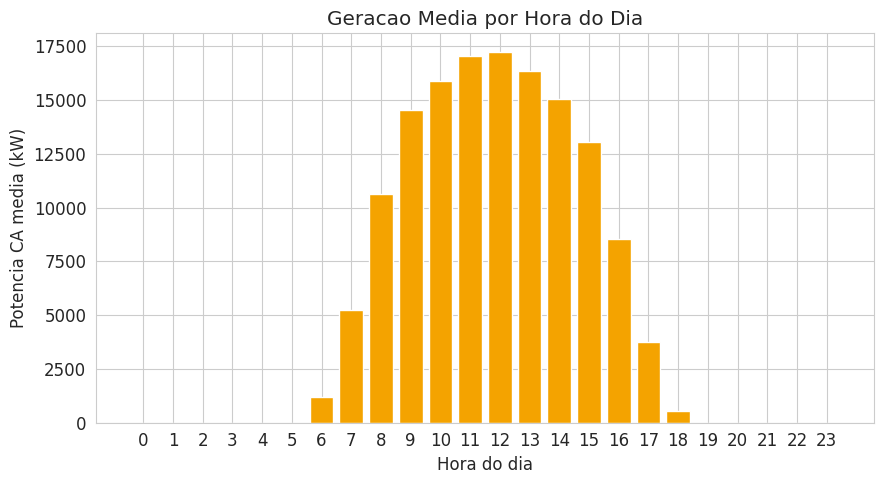

Geracao concentrada entre ~6h e ~18h, com pico ao meio-dia. A relacao com a hora e nao-linear.


In [42]:
# 3.2 Geracao media por hora do dia
# Mostra o ciclo diurno e justifica o uso da hora como atributo.
por_hora = df.groupby('HORA')['AC_POWER'].mean()

plt.figure(figsize=(9, 5))
plt.bar(por_hora.index, por_hora.values, color=COLORS[0])
plt.xlabel('Hora do dia')
plt.ylabel('Potencia CA media (kW)')
plt.title('Geracao Media por Hora do Dia')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig('aed_geracao_hora.png', dpi=150, bbox_inches='tight')
plt.show()

print('Geracao concentrada entre ~6h e ~18h, com pico ao meio-dia. A relacao com a hora e nao-linear.')

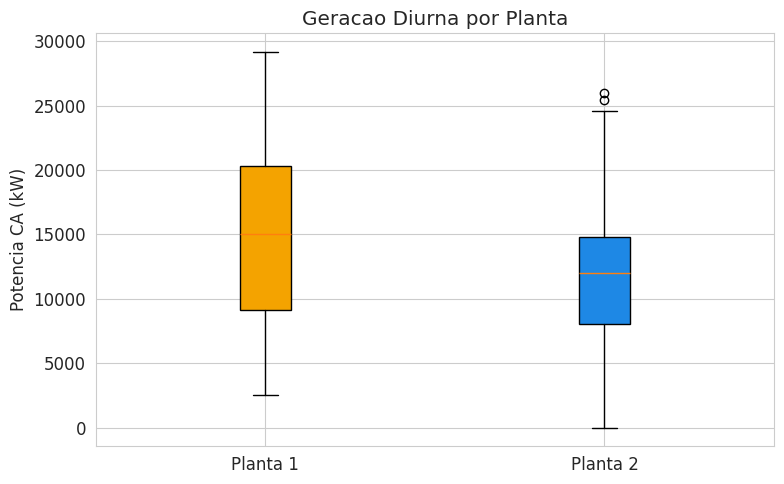

As plantas apresentam niveis de geracao distintos; por isso PLANT_ID entra como atributo.


In [43]:
# 3.3 Geracao diurna por planta
# Verifica se as plantas operam em niveis diferentes, justificando PLANT_ID.
df_dia = df[df['IRRADIATION'] > 0.1]
dados = [df_dia[df_dia['PLANT_ID'] == 1]['AC_POWER'],
         df_dia[df_dia['PLANT_ID'] == 2]['AC_POWER']]

plt.figure(figsize=(8, 5))
bp = plt.boxplot(dados, labels=['Planta 1', 'Planta 2'], patch_artist=True)
for patch, color in zip(bp['boxes'], [COLORS[0], COLORS[1]]):
    patch.set_facecolor(color)
plt.ylabel('Potencia CA (kW)')
plt.title('Geracao Diurna por Planta')
plt.tight_layout()
plt.savefig('aed_geracao_planta.png', dpi=150, bbox_inches='tight')
plt.show()

print('As plantas apresentam niveis de geracao distintos; por isso PLANT_ID entra como atributo.')

### Sintese da analise

- A **irradiacao** e o principal fator de geracao e e o atributo central da regressao.
- A geracao segue um **ciclo diurno** nao-linear, capturado pela `HORA`.
- As duas plantas geram em **niveis diferentes**, o que justifica usar `PLANT_ID`.

A potencia DC (`DC_POWER`) **nao** e usada como atributo. Ela e medida no mesmo instante da geracao e e quase proporcional a ela; us-la tornaria o modelo dependente de uma leitura que so existe quando a usina ja esta gerando, impedindo a previsao antecipada. Usando apenas variaveis climaticas, o mesmo modelo serve para prever e para monitorar.

---
## 4. Preparacao para Modelagem

### 4.1 Atributos

Apenas variaveis climaticas e de contexto, sem nenhuma leitura de geracao como entrada:

| Atributo | Justificativa |
|---|---|
| IRRADIATION | Principal fator de geracao |
| MODULE_TEMPERATURE | Condicao termica do painel |
| AMBIENT_TEMPERATURE | Condicao climatica do ambiente |
| HORA | Captura o ciclo diurno |
| PLANT_ID | Distingue o nivel de geracao de cada planta |

In [44]:
# 4.1 Definicao de atributos e alvos
FEATURES = ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'HORA', 'PLANT_ID']
TARGET_REG   = 'AC_POWER'        # regressao: geracao esperada
TARGET_CLASS = 'BAIXA_GERACAO'   # classificacao: periodo de baixa geracao

# Ambas as tarefas usam apenas periodos com sol (irradiacao > 0.1):
# nao se preve nem se monitora geracao a noite.
base = df[df['IRRADIATION'] > 0.1].copy()
df_model = base[FEATURES + [TARGET_REG, TARGET_CLASS]].dropna()
print(f'Amostras (periodos diurnos): {len(df_model)}')

X       = df_model[FEATURES]
y_reg   = df_model[TARGET_REG]
y_class = df_model[TARGET_CLASS]

print(f'Atributos: {FEATURES}')
print(f'Regressao (AC_POWER): min={y_reg.min():.0f}, max={y_reg.max():.0f}')
print(f'Classificacao (BAIXA_GERACAO):\n{y_class.value_counts()}')

Amostras (periodos diurnos): 2789
Atributos: ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'HORA', 'PLANT_ID']
Regressao (AC_POWER): min=0, max=29150
Classificacao (BAIXA_GERACAO):
BAIXA_GERACAO
0    1673
1    1116
Name: count, dtype: int64


In [45]:
# 4.2 Divisao treino/teste
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class)

print(f'Treino regressao:     {X_train_r.shape[0]}')
print(f'Teste regressao:      {X_test_r.shape[0]}')
print(f'Treino classificacao: {X_train_c.shape[0]}')
print(f'Teste classificacao:  {X_test_c.shape[0]}')

Treino regressao:     2231
Teste regressao:      558
Treino classificacao: 2231
Teste classificacao:  558


In [46]:
# 4.3 Normalizacao
# Regressao Linear e Random Forest usam os dados originais; o MLP usa os
# dados normalizados (StandardScaler) para convergir melhor.
scaler = StandardScaler()
X_train_r_sc = scaler.fit_transform(X_train_r)
X_test_r_sc  = scaler.transform(X_test_r)

scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc  = scaler_c.transform(X_test_c)

print('Normalizacao aplicada.')

Normalizacao aplicada.


---
## 5. Regressao - Geracao Esperada (AC_POWER)

Preve a potencia CA a partir das condicoes climaticas. Esse valor serve para previsao (planejamento) e como referencia de monitoramento (comparacao com a geracao real). Modelos: Regressao Linear (baseline), Random Forest e MLP.

In [47]:
# ── 5.1 Métricas helper ───────────────────────────────────────────────────────
def avaliar_regressao(nome, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'[{nome}]  RMSE: {rmse:.2f} | MAE: {mae:.2f} | R²: {r2:.4f}')
    return {'Modelo': nome, 'RMSE': rmse, 'MAE': mae, 'R²': r2}

In [48]:
# ── 5.2 Regressão Linear (Baseline) ──────────────────────────────────────────
lr = LinearRegression()
lr.fit(X_train_r, y_train_r)
pred_lr = lr.predict(X_test_r)
res_lr = avaliar_regressao('Regressão Linear', y_test_r, pred_lr)

# Coeficientes
coef_df = pd.DataFrame({'Feature': FEATURES, 'Coeficiente': lr.coef_}).sort_values('Coeficiente', ascending=False)
print('\nCoeficientes:')
print(coef_df.to_string(index=False))

[Regressão Linear]  RMSE: 3337.25 | MAE: 2434.03 | R²: 0.7090

Coeficientes:
            Feature  Coeficiente
        IRRADIATION 18452.576188
               HORA    98.482817
 MODULE_TEMPERATURE    45.900553
AMBIENT_TEMPERATURE  -121.731858
           PLANT_ID -3505.909585


In [49]:
# ── 5.3 Random Forest Regressor ───────────────────────────────────────────────
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_reg.fit(X_train_r, y_train_r)
pred_rf = rf_reg.predict(X_test_r)
res_rf = avaliar_regressao('Random Forest', y_test_r, pred_rf)

# Feature importance
fi = pd.DataFrame({'Feature': FEATURES, 'Importância': rf_reg.feature_importances_})
fi = fi.sort_values('Importância', ascending=False)
print('\nImportância das Features (Random Forest):')
print(fi.to_string(index=False))

[Random Forest]  RMSE: 2410.32 | MAE: 1332.18 | R²: 0.8482

Importância das Features (Random Forest):
            Feature  Importância
        IRRADIATION     0.794377
           PLANT_ID     0.122244
AMBIENT_TEMPERATURE     0.035502
 MODULE_TEMPERATURE     0.032360
               HORA     0.015517


In [50]:
# ── 5.4 MLP Regressor (Rede Neural) ──────────────────────────────────────────
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)
mlp_reg.fit(X_train_r_sc, y_train_r)
pred_mlp = mlp_reg.predict(X_test_r_sc)
res_mlp = avaliar_regressao('MLP (Rede Neural)', y_test_r, pred_mlp)

[MLP (Rede Neural)]  RMSE: 2412.51 | MAE: 1361.62 | R²: 0.8479


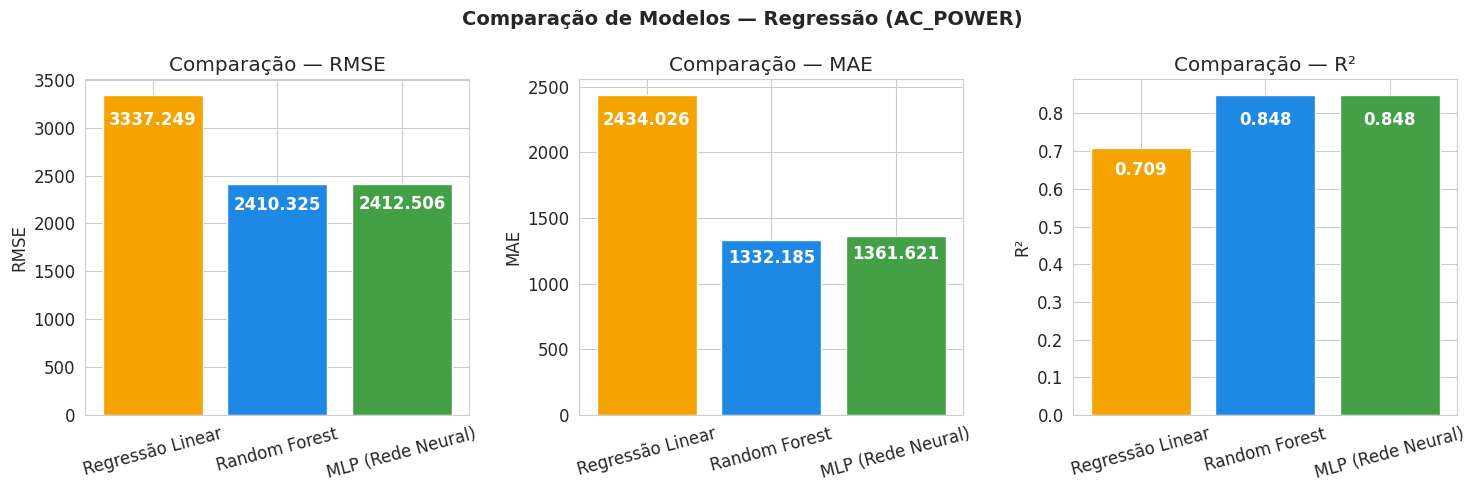


=== Tabela Comparativa ===
           Modelo        RMSE         MAE       R²
 Regressão Linear 3337.248720 2434.026494 0.709008
    Random Forest 2410.324994 1332.184795 0.848206
MLP (Rede Neural) 2412.506051 1361.621317 0.847931


In [51]:
# ── 5.5 Comparação Visual dos Modelos de Regressão ───────────────────────────
resultados_reg = pd.DataFrame([res_lr, res_rf, res_mlp])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metricas = ['RMSE', 'MAE', 'R²']
for i, metrica in enumerate(metricas):
    bars = axes[i].bar(resultados_reg['Modelo'], resultados_reg[metrica],
                       color=COLORS[:3])
    axes[i].set_title(f'Comparação — {metrica}')
    axes[i].set_ylabel(metrica)
    axes[i].tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, resultados_reg[metrica]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 0.95,
                     f'{val:.3f}', ha='center', va='top', color='white', fontweight='bold')

plt.suptitle('Comparação de Modelos — Regressão (AC_POWER)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('comparacao_regressao.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Tabela Comparativa ===')
print(resultados_reg.to_string(index=False))

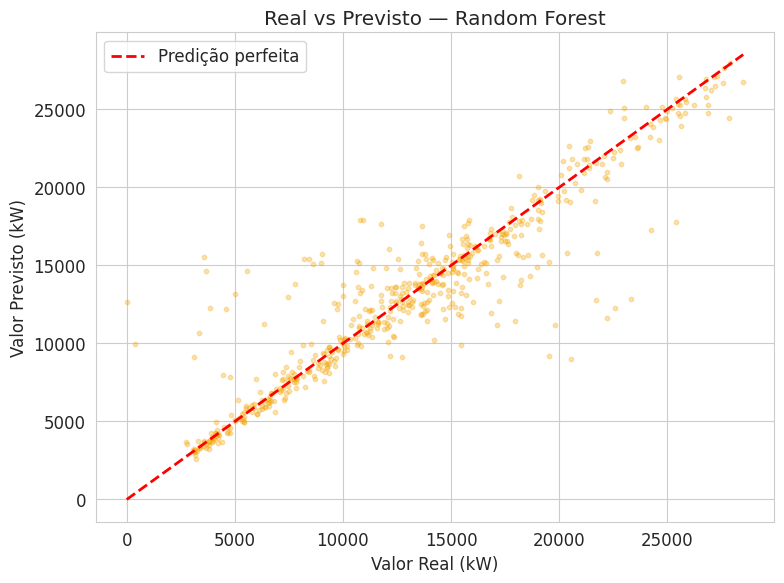

In [52]:
# ── 5.6 Real vs Previsto — Melhor Modelo
# Identifica automaticamente o modelo com maior R²
melhor_idx = resultados_reg['R²'].idxmax()
melhor_nome = resultados_reg.loc[melhor_idx, 'Modelo']
preds_map = {'Regressão Linear': pred_lr, 'Random Forest': pred_rf, 'MLP (Rede Neural)': pred_mlp}
melhor_pred = preds_map[melhor_nome]

plt.figure(figsize=(8, 6))
plt.scatter(y_test_r, melhor_pred, alpha=0.3, color=COLORS[0], s=10)
lim = [min(y_test_r.min(), melhor_pred.min()), max(y_test_r.max(), melhor_pred.max())]
plt.plot(lim, lim, 'r--', linewidth=2, label='Predição perfeita')
plt.xlabel('Valor Real (kW)')
plt.ylabel('Valor Previsto (kW)')
plt.title(f'Real vs Previsto — {melhor_nome}')
plt.legend()
plt.tight_layout()
plt.savefig('real_vs_previsto.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Classificacao - Previsao de Baixa Geracao

Preve, a partir do clima, se o periodo tera baixa geracao (os 40% menores valores diurnos de cada planta). Apoia o planejamento operacional, como agendar manutencoes em janelas de menor producao. Modelos: Regressao Logistica (baseline), Random Forest e MLP.

In [53]:
# 6.1 Metrica helper
def avaliar_classificacao(nome, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    print(f'[{nome}]  Acuracia: {acc:.4f}' + (f' | AUC-ROC: {auc:.4f}' if auc else ''))
    print(classification_report(y_true, y_pred, target_names=['Geracao Adequada', 'Baixa Geracao']))
    return {'Modelo': nome, 'Acurácia': acc, 'AUC-ROC': auc if auc else 0}

In [54]:
# 6.2 Regressao Logistica (baseline)
# class_weight='balanced' compensa o leve desbalanceamento entre as classes.
logr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
logr.fit(X_train_c_sc, y_train_c)
pred_logr = logr.predict(X_test_c_sc)
prob_logr = logr.predict_proba(X_test_c_sc)[:, 1]
res_logr  = avaliar_classificacao('Regressao Logistica', y_test_c, pred_logr, prob_logr)

[Regressao Logistica]  Acuracia: 0.8548 | AUC-ROC: 0.9300
                  precision    recall  f1-score   support

Geracao Adequada       0.92      0.83      0.87       335
   Baixa Geracao       0.78      0.90      0.83       223

        accuracy                           0.85       558
       macro avg       0.85      0.86      0.85       558
    weighted avg       0.86      0.85      0.86       558



In [55]:
# 6.3 Random Forest Classifier
rf_cls = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
rf_cls.fit(X_train_c, y_train_c)
pred_rfc = rf_cls.predict(X_test_c)
prob_rfc = rf_cls.predict_proba(X_test_c)[:, 1]
res_rfc  = avaliar_classificacao('Random Forest', y_test_c, pred_rfc, prob_rfc)

# Importancia dos atributos na previsao de baixa geracao
fi_cls = pd.DataFrame({'Feature': FEATURES, 'Importancia': rf_cls.feature_importances_})
fi_cls = fi_cls.sort_values('Importancia', ascending=False)
print('\nImportancia dos atributos (baixa geracao):')
print(fi_cls.to_string(index=False))

[Random Forest]  Acuracia: 0.9283 | AUC-ROC: 0.9750
                  precision    recall  f1-score   support

Geracao Adequada       0.92      0.97      0.94       335
   Baixa Geracao       0.95      0.87      0.91       223

        accuracy                           0.93       558
       macro avg       0.93      0.92      0.92       558
    weighted avg       0.93      0.93      0.93       558


Importancia dos atributos (baixa geracao):
            Feature  Importancia
        IRRADIATION     0.534852
 MODULE_TEMPERATURE     0.247503
AMBIENT_TEMPERATURE     0.115190
               HORA     0.073671
           PLANT_ID     0.028784


In [56]:
# ── 6.4 MLP Classifier (Rede Neural) ─────────────────────────────────────────
mlp_cls = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    max_iter=500,
    random_state=42,
    early_stopping=True
)
mlp_cls.fit(X_train_c_sc, y_train_c)
pred_mlpc = mlp_cls.predict(X_test_c_sc)
prob_mlpc = mlp_cls.predict_proba(X_test_c_sc)[:, 1]
res_mlpc  = avaliar_classificacao('MLP (Rede Neural)', y_test_c, pred_mlpc, prob_mlpc)

[MLP (Rede Neural)]  Acuracia: 0.8996 | AUC-ROC: 0.9545
                  precision    recall  f1-score   support

Geracao Adequada       0.89      0.95      0.92       335
   Baixa Geracao       0.91      0.83      0.87       223

        accuracy                           0.90       558
       macro avg       0.90      0.89      0.89       558
    weighted avg       0.90      0.90      0.90       558



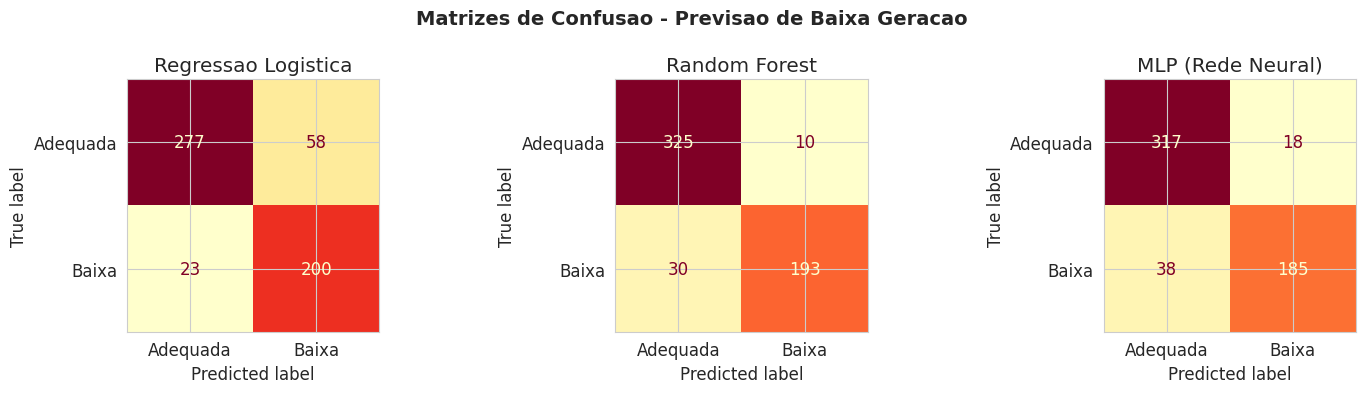

In [57]:
# 6.5 Matrizes de Confusao
modelos_cls = [
    ('Regressao Logistica', pred_logr),
    ('Random Forest',       pred_rfc),
    ('MLP (Rede Neural)',   pred_mlpc),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, pred) in zip(axes, modelos_cls):
    cm = confusion_matrix(y_test_c, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Adequada', 'Baixa'])
    disp.plot(ax=ax, colorbar=False, cmap='YlOrRd')
    ax.set_title(nome)

plt.suptitle('Matrizes de Confusao - Previsao de Baixa Geracao', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('matrizes_confusao.png', dpi=150, bbox_inches='tight')
plt.show()

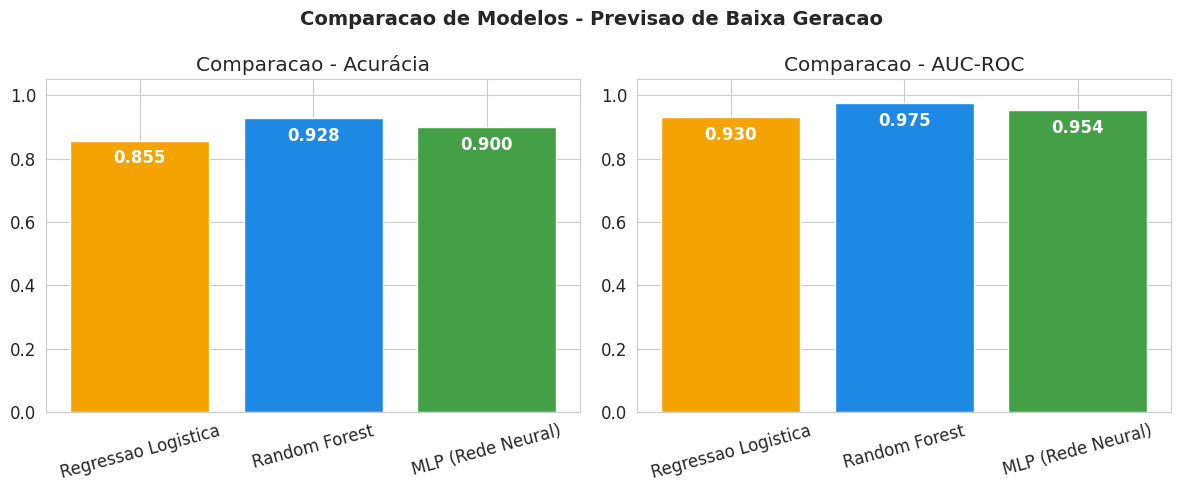


=== Tabela Comparativa ===
             Modelo  Acurácia  AUC-ROC
Regressao Logistica  0.854839 0.929991
      Random Forest  0.928315 0.975035
  MLP (Rede Neural)  0.899642 0.954474


In [58]:
# 6.7 Comparacao final - Classificacao
resultados_cls = pd.DataFrame([res_logr, res_rfc, res_mlpc])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, metrica in enumerate(['Acurácia', 'AUC-ROC']):
    bars = axes[i].bar(resultados_cls['Modelo'], resultados_cls[metrica], color=COLORS[:3])
    axes[i].set_title(f'Comparacao - {metrica}')
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, resultados_cls[metrica]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 0.97,
                     f'{val:.3f}', ha='center', va='top', color='white', fontweight='bold')

plt.suptitle('Comparacao de Modelos - Previsao de Baixa Geracao', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('comparacao_classificacao.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Tabela Comparativa ===')
print(resultados_cls.to_string(index=False))

---
## 7. Relatorio de Decisao para o Gestor

Integra os dois modelos a partir apenas das condicoes climaticas:
1. geracao CA esperada (regressao) - referencia para previsao e monitoramento;
2. previsao de baixa geracao (classificacao) - apoio ao planejamento;
3. quando ha leitura real da geracao, o desvio entre esperado e real e a recomendacao de monitoramento.

In [59]:
def relatorio_gestor(irradiacao, temp_modulo, temp_ambiente, hora, plant_id, ac_power_real=None):
    """
    Relatorio de apoio a decisao a partir das condicoes climaticas.

    Parametros:
        irradiacao, temp_modulo, temp_ambiente, hora, plant_id: condicoes (atuais ou previstas)
        ac_power_real (opcional): geracao CA realmente medida. Se informada,
            o sistema compara com a esperada (monitoramento).
    """
    entrada = np.array([[irradiacao, temp_modulo, temp_ambiente, hora, plant_id]])
    geracao_esperada = rf_reg.predict(entrada)[0]
    baixa_geracao    = rf_cls.predict(entrada)[0]
    prob_baixa       = rf_cls.predict_proba(entrada)[0][1]

    print('=' * 55)
    print('   RELATORIO DE APOIO A DECISAO - USINA SOLAR')
    print('=' * 55)
    print(f'  Planta:               {plant_id}')
    print(f'  Irradiacao:           {irradiacao:.2f}')
    print(f'  Temp. Modulo:         {temp_modulo:.1f} C')
    print(f'  Temp. Ambiente:       {temp_ambiente:.1f} C')
    print(f'  Hora:                 {hora}h')
    print('-' * 55)
    print(f'  Geracao CA Esperada:  {geracao_esperada:.1f} kW')
    print(f'  Previsao do Periodo:  {"BAIXA GERACAO" if baixa_geracao == 1 else "GERACAO ADEQUADA"} '
          f'({prob_baixa*100:.1f}% prob. de baixa)')

    if ac_power_real is not None:
        desvio = geracao_esperada - ac_power_real
        desvio_pct = (desvio / geracao_esperada * 100) if geracao_esperada > 0 else 0
        print('-' * 55)
        print(f'  Geracao CA Real:      {ac_power_real:.1f} kW')
        print(f'  Desvio (Esp - Real):  {desvio:.1f} kW ({desvio_pct:.1f}%)')
        if ac_power_real < geracao_esperada * 0.85:
            recomendacao = 'Geracao real abaixo do esperado para as condicoes. Possivel falha ou sujeira; recomenda-se inspecao.'
        else:
            recomendacao = 'Geracao real coerente com o esperado. Operacao normal.'
    else:
        if baixa_geracao == 1:
            recomendacao = 'Previsao de baixa geracao. Janela adequada para manutencoes programadas.'
        else:
            recomendacao = 'Previsao de geracao adequada.'

    print('-' * 55)
    print(f'  Recomendacao: {recomendacao}')
    print('=' * 55)


# Exemplo 1 - Planejamento: condicoes boas, previsao de geracao
relatorio_gestor(irradiacao=0.85, temp_modulo=50, temp_ambiente=32, hora=12, plant_id=1)

print()

# Exemplo 2 - Planejamento: baixa irradiacao, previsao de baixa geracao
relatorio_gestor(irradiacao=0.20, temp_modulo=28, temp_ambiente=24, hora=9, plant_id=1)

print()

# Exemplo 3 - Monitoramento: geracao real bem abaixo do esperado
relatorio_gestor(irradiacao=0.85, temp_modulo=50, temp_ambiente=32, hora=12, plant_id=2, ac_power_real=5000)

   RELATORIO DE APOIO A DECISAO - USINA SOLAR
  Planta:               1
  Irradiacao:           0.85
  Temp. Modulo:         50.0 C
  Temp. Ambiente:       32.0 C
  Hora:                 12h
-------------------------------------------------------
  Geracao CA Esperada:  24426.3 kW
  Previsao do Periodo:  GERACAO ADEQUADA (0.0% prob. de baixa)
-------------------------------------------------------
  Recomendacao: Previsao de geracao adequada.

   RELATORIO DE APOIO A DECISAO - USINA SOLAR
  Planta:               1
  Irradiacao:           0.20
  Temp. Modulo:         28.0 C
  Temp. Ambiente:       24.0 C
  Hora:                 9h
-------------------------------------------------------
  Geracao CA Esperada:  6380.3 kW
  Previsao do Periodo:  BAIXA GERACAO (99.0% prob. de baixa)
-------------------------------------------------------
  Recomendacao: Previsao de baixa geracao. Janela adequada para manutencoes programadas.

   RELATORIO DE APOIO A DECISAO - USINA SOLAR
  Planta:          

---
## 8. Prototipo de Interface - Painel de Apoio a Decisao

Painel interativo (`ipywidgets`) que usa apenas as condicoes climaticas. O usuario seleciona a planta e ajusta as condicoes (atuais ou previstas); o sistema retorna a geracao esperada e a previsao de baixa geracao. Informando a geracao real medida, o painel calcula o desvio e a recomendacao de monitoramento.

In [60]:
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
import matplotlib.pyplot as plt

# Faixa de geracao CA por planta (para o slider de leitura real)
ac_ranges = df_model.groupby('PLANT_ID')['AC_POWER'].max()

COR_LARANJA  = '#F57C00'
COR_AZUL     = '#1E88E5'
COR_VERDE    = '#2E7D32'
COR_VERMELHO = '#C62828'
COR_AMARELO  = '#EF6C00'

estilo = {'description_width': '150px'}
plant_dd        = widgets.Dropdown(options=[1, 2], value=1, description='Planta:', style=estilo)
hora_slider     = widgets.IntSlider(min=5, max=19, value=12, description='Hora do dia:', style=estilo)
irrad_slider    = widgets.FloatSlider(min=0.0, max=1.2, step=0.01, value=0.80, description='Irradiacao:', style=estilo)
temp_mod_slider = widgets.FloatSlider(min=15, max=70, value=45, description='Temp. Modulo (C):', style=estilo)
temp_amb_slider = widgets.FloatSlider(min=15, max=40, value=28, description='Temp. Ambiente (C):', style=estilo)
ac_real_checkbox = widgets.Checkbox(value=False, description='Tenho leitura real de geracao (monitoramento)')
ac_real_slider   = widgets.FloatSlider(description='Geracao CA Real (kW):', style=estilo, readout_format='.0f', disabled=True)
gerar_button = widgets.Button(description='Gerar Relatorio', button_style='primary',
                              layout=widgets.Layout(width='200px', height='36px'))
output_area = widgets.Output()


def atualizar_faixa_ac(*args):
    ac_max = float(ac_ranges.loc[plant_dd.value])
    ac_real_slider.min, ac_real_slider.max = 0, ac_max
    ac_real_slider.value = ac_max * 0.6

def alternar_ac_real(*args):
    ac_real_slider.disabled = not ac_real_checkbox.value

plant_dd.observe(atualizar_faixa_ac, names='value')
ac_real_checkbox.observe(alternar_ac_real, names='value')
atualizar_faixa_ac()


def card(titulo, valor, subtitulo, cor):
    return f"""
    <div style="flex:1; background:#FAFAFA; border-radius:10px; overflow:hidden;
                box-shadow:0 1px 4px rgba(0,0,0,0.12);">
        <div style="height:5px; background:{cor};"></div>
        <div style="padding:14px 12px; text-align:center;">
            <div style="font-size:12px; color:#666666;">{titulo}</div>
            <div style="font-size:24px; font-weight:700; color:{cor}; margin-top:3px;">{valor}</div>
            <div style="font-size:11px; color:#9E9E9E; margin-top:3px;">{subtitulo}</div>
        </div>
    </div>
    """


def gerar_relatorio(b):
    with output_area:
        clear_output()
        plant_id      = plant_dd.value
        hora          = hora_slider.value
        irradiacao    = irrad_slider.value
        temp_modulo   = temp_mod_slider.value
        temp_ambiente = temp_amb_slider.value
        usar_real     = ac_real_checkbox.value
        ac_power_real = ac_real_slider.value if usar_real else None

        entrada = np.array([[irradiacao, temp_modulo, temp_ambiente, hora, plant_id]])
        geracao_esperada = rf_reg.predict(entrada)[0]
        baixa_geracao    = rf_cls.predict(entrada)[0]
        prob_baixa       = rf_cls.predict_proba(entrada)[0][1]

        # Recomendacao
        if usar_real:
            desvio = geracao_esperada - ac_power_real
            desvio_pct = (desvio / geracao_esperada * 100) if geracao_esperada > 0 else 0
            if ac_power_real < geracao_esperada * 0.85:
                nivel = 'critico'
                recomendacao = 'Geracao real abaixo do esperado para as condicoes. Possivel falha ou sujeira; recomenda-se inspecao.'
            else:
                nivel = 'normal'
                recomendacao = 'Geracao real coerente com o esperado. Operacao normal.'
        else:
            if baixa_geracao == 1:
                nivel = 'atencao'
                recomendacao = 'Previsao de baixa geracao. Janela adequada para manutencoes programadas.'
            else:
                nivel = 'normal'
                recomendacao = 'Previsao de geracao adequada.'

        estilos = {
            'normal':  {'bg': '#E8F5E9', 'cor': COR_VERDE,    'titulo': 'OPERACAO NORMAL'},
            'atencao': {'bg': '#FFF3E0', 'cor': COR_AMARELO,  'titulo': 'PLANEJAMENTO'},
            'critico': {'bg': '#FFEBEE', 'cor': COR_VERMELHO, 'titulo': 'ACAO NECESSARIA'},
        }
        est = estilos[nivel]
        cor_baixa = COR_VERMELHO if baixa_geracao == 1 else COR_VERDE

        html = f"""
        <div style="background:#FFFFFF; color:#212121; font-family:'Segoe UI', Arial, sans-serif;
                    border-radius:14px; padding:20px; box-shadow:0 2px 10px rgba(0,0,0,0.15);">
            <div style="background:#F57C00; border-radius:10px; padding:14px 18px;
                        color:#FFFFFF; margin-bottom:16px;">
                <div style="font-size:18px; font-weight:700;">Relatorio de Apoio a Decisao</div>
                <div style="font-size:13px; opacity:0.9;">Planta {plant_id} - {hora}h - Irradiacao {irradiacao:.2f}</div>
            </div>
            <div style="display:flex; gap:12px; margin-bottom:16px;">
                {card('Geracao CA Esperada', f'{geracao_esperada:,.0f} kW', 'previsao a partir do clima', COR_LARANJA)}
        """
        if usar_real:
            html += card('Geracao CA Real', f'{ac_power_real:,.0f} kW',
                         f'desvio: {desvio_pct:.0f}%', COR_AZUL)
        html += card('Previsao do Periodo',
                     'Baixa' if baixa_geracao == 1 else 'Adequada',
                     f'{prob_baixa*100:.1f}% prob. de baixa', cor_baixa)
        html += "</div>"

        html += f"""
            <div style="background:{est['bg']}; border-left:5px solid {est['cor']};
                        border-radius:8px; padding:14px 16px; margin-top:8px;">
                <div style="color:{est['cor']}; font-weight:700; font-size:14px;">{est['titulo']}</div>
                <div style="color:#424242; font-size:13px; margin-top:4px;">{recomendacao}</div>
            </div>
        </div>
        """
        display(HTML(html))

        if usar_real:
            fig, ax = plt.subplots(figsize=(5, 2.8))
            barras = ax.bar(['Esperado', 'Real'], [geracao_esperada, ac_power_real],
                            color=[COR_LARANJA, COR_AZUL], width=0.5)
            for bar, val in zip(barras, [geracao_esperada, ac_power_real]):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{val:,.0f}',
                        ha='center', va='bottom', fontweight='bold', fontsize=10)
            ax.set_ylabel('Potencia CA (kW)')
            ax.set_title('Geracao Esperada vs Real', fontsize=12)
            ax.spines[['top', 'right']].set_visible(False)
            plt.tight_layout()
            plt.show()


gerar_button.on_click(gerar_relatorio)

display(HTML("""
<div style="background:#FFF3E0; border-radius:12px; padding:16px 20px; margin-bottom:12px; color:#5D4037;">
    <h2 style="margin:0; color:#5D4037;">Painel de Apoio a Decisao - Usina Solar</h2>
    <div style="font-size:13px;">Ajuste as condicoes climaticas. Marque a leitura real para o modo de monitoramento.</div>
</div>
"""))

# Using GridspecLayout for better organization

grid = widgets.GridspecLayout(4, 2, width='auto')

grid[0, 0] = plant_dd
grid[0, 1] = hora_slider
grid[1, 0] = irrad_slider
grid[2, 0] = temp_mod_slider
grid[1, 1] = temp_amb_slider
grid[3, 1] = ac_real_checkbox
grid[2, 1] = ac_real_slider

display(grid)
display(gerar_button)
display(output_area)

GridspecLayout(children=(Dropdown(description='Planta:', layout=Layout(grid_area='widget001'), options=(1, 2),…

Button(button_style='primary', description='Gerar Relatorio', layout=Layout(height='36px', width='200px'), sty…

Output()

## 9. Conclusoes

### Resultados

Preencher as tabelas com os valores obtidos ao executar o notebook.

**Regressao - Geracao Esperada (AC_POWER)**

| Modelo            | RMSE        | MAE         | R²       |
|:------------------|:------------|:------------|:---------|
| Regressão Linear  | 3337.248720 | 2434.026494 | 0.709008 |
| Random Forest     | 2410.324994 | 1332.184795 | 0.848206 |
| MLP (Rede Neural) | 2412.506051 | 1361.621317 | 0.847931 |

**Classificacao - Previsao de Baixa Geracao**

| Modelo              | Acurácia | AUC-ROC  |
|:--------------------|:---------|:---------|
| Regressao Logistica | 0.854839 | 0.929991 |
| Random Forest       | 0.928315 | 0.975035 |
| MLP (Rede Neural)   | 0.899642 | 0.954474 |
  
### Conclusoes da analise

- A irradiacao e o principal fator de geracao; a hora captura o ciclo diurno (relacao nao-linear), o que favorece modelos baseados em arvores e redes neurais.
- O modelo usa apenas variaveis climaticas, sem a potencia DC. Por isso serve tanto para prever a geracao futura quanto para monitorar a usina, comparando a geracao real com a esperada.
- Regressao (valor esperado) e classificacao (previsao de baixa geracao) atuam de forma complementar: a primeira da a referencia quantitativa e a base do monitoramento; a segunda da um sinal binario para planejamento.

### Decisoes metodologicas relevantes

- Exclusao da potencia DC como atributo: ela e medida junto com a geracao e e quase proporcional a ela, o que impediria a previsao antecipada.
- Modelagem restrita a periodos com sol (irradiacao > 0.1), ja que nao se preve nem se monitora geracao a noite.
- IQR descartado para tratamento de outliers (removia picos legitimos de geracao); mantida apenas a verificacao de plausibilidade fisica.
- class_weight='balanced' na classificacao para lidar com o desbalanceamento entre as classes.